# Thick Cloud Removal Using Cloud Mask-Guided SAR-Optical Fusion — Training Notebook

**Base paper:** S. Meng *et al.*, "Thick Cloud Removal Using Cloud Mask-Guided SAR-Optical Fusion Network (PSF-CR)", *IEEE JSTARS*, vol. 19, pp. 4373-4388, 2026, DOI 10.1109/JSTARS.2026.3651496.

**Task:** reconstruct a cloud-free 13-band Sentinel-2 image from a cloudy Sentinel-2 image + co-registered Sentinel-1 SAR (VV, VH) + cloud mask (pixel-wise image regression).

**Data:** real SEN12MS-CR-style triplets (S1 / cloudy S2 / cloud-free S2, 256×256, 10 m) built from public Copernicus Sentinel-1 RTC and Sentinel-2 L1C archives (see `data/README.md`).

**Models trained**
| # | Model | Role |
|---|---|---|
| 1 | DSen2-CR | Existing baseline used in the paper |
| 2 | PSF-CR | Paper's method (SFFA = FGCA + SLCA, CMGR, MCL/SLSA/FGSA U-Net, composite loss) |
| 3 | Restormer-CR | Advanced transformer (Restormer, CVPR 2022) adapted to SAR-optical, mask-guided fusion |
| 4 | PSF-CR++ | Proposed advanced model: PSF-CR + gated-Dconv FFN, transposed-attention bottleneck, mask-aware adaptive output fusion |

**Metrics (as in the paper):** PSNR, SSIM, SAM, MAE; plus cloudy vs cloud-free region and per-band analysis.

## 1. Import Required Libraries
Imports numerical, geospatial, plotting and PyTorch libraries.

In [1]:
import os, json, time, math, random, warnings
import numpy as np
import pandas as pd
import rasterio
import matplotlib.pyplot as plt
from scipy import ndimage, signal
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from pytorch_msssim import ssim as ssim_fn
warnings.filterwarnings("ignore")
print("torch", torch.__version__, "| rasterio", rasterio.__version__, "| numpy", np.__version__)

torch 2.14.1+cu130 | rasterio 1.5.2 | numpy 2.5.3


## 2. Project Configuration
Defines paths, random seed, preprocessing constants (from the paper) and training hyper-parameters.

In [2]:
ROOT = os.path.abspath("..")
RAW_DIR = os.path.join(ROOT, "data", "raw", "sen12mscr_style")
PROC_DIR = os.path.join(ROOT, "data", "processed")
MODEL_DIR = os.path.join(ROOT, "models")
EVAL_DIR = os.path.join(MODEL_DIR, "model_evaluation_results")
for d in (PROC_DIR, MODEL_DIR, EVAL_DIR): os.makedirs(d, exist_ok=True)

try:   # Linux/glibc: keep freed memory in the heap instead of mmap/munmap for every large tensor (2x faster on CPU)
    import ctypes; _libc = ctypes.CDLL("libc.so.6"); _libc.mallopt(-3, 2 ** 30); _libc.mallopt(-1, 2 ** 31 - 1)
except Exception:
    pass
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(max(1, os.cpu_count()))
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

BANDS = ["B01","B02","B03","B04","B05","B06","B07","B08","B8A","B09","B10","B11","B12"]
PREPROC = {
    "s2_bands": BANDS,
    "s1_bands": ["VV", "VH"],
    "s1_clip_db": {"VV": [-25.0, 0.0], "VH": [-32.5, 0.0]},   # paper Sec. IV-A-2
    "s2_clip": [0.0, 10000.0],                                  # paper Sec. IV-A-2
    "cloud_threshold": 0.2,                                     # rule-based cloud detector threshold
    "cloud_rules": {"B02": [0.1, 0.5], "B01": [0.1, 0.3], "B01+B10": [0.15, 0.2], "B02+B03+B04": [0.2, 0.8], "NDSI(B03,B11)": [0.8, 0.6]},
    "cloud_closing_size": 5, "cloud_box_size": 7,
    "patch_size": 256,
}
TRAIN_CFG = {"crop": 128, "batch_size": 4, "epochs": 6, "lr": 2e-4, "lr_min": 2e-6, "weight_decay": 1e-4,
             "betas": (0.9, 0.999), "lambda_spa": 1.0, "lambda_freq": 0.1, "alpha_ssim": 0.1, "n_val_monitor": 40}
print(DEVICE, json.dumps(TRAIN_CFG))

cpu {"crop": 128, "batch_size": 4, "epochs": 6, "lr": 0.0002, "lr_min": 2e-06, "weight_decay": 0.0001, "betas": [0.9, 0.999], "lambda_spa": 1.0, "lambda_freq": 0.1, "alpha_ssim": 0.1, "n_val_monitor": 40}


## 3. Load Dataset Metadata
Loads the patch-level metadata table produced when the triplets were extracted.

In [3]:
meta = pd.read_csv(os.path.join(RAW_DIR, "metadata.csv"))
print("patches:", len(meta), "| ROIs (S1 scenes):", meta.roi.nunique(), "| S2 tiles:", meta.tile.nunique())
meta.head()

patches: 1149 | ROIs (S1 scenes): 8 | S2 tiles: 19


,patch,pair_id,roi,tile,s1_scene,s2_cloudy,s2_clear,cloudy_date,clear_date,cloud_frac,lon,lat,crs
0,20190102T111147_48PUT_20181230_p0036,20190102T111147_48PUT_20181230,20190102T111147,48PUT,S1A_IW_GRDH_1SDV_20190102T111147_20190102T1112...,S2B_MSIL1C_20181230T033139_N0207_R018_T48PUT_2...,S2A_MSIL1C_20181225T033141_N0207_R018_T48PUT_2...,20181230,20181225,0.387741,104.022067,11.746794,EPSG:32648
1,20190102T111147_48PUT_20181230_p0340,20190102T111147_48PUT_20181230,20190102T111147,48PUT,S1A_IW_GRDH_1SDV_20190102T111147_20190102T1112...,S2B_MSIL1C_20181230T033139_N0207_R018_T48PUT_2...,S2A_MSIL1C_20181225T033141_N0207_R018_T48PUT_2...,20181230,20181225,0.316086,104.116255,11.677654,EPSG:32648
2,20190102T111147_48PUT_20181230_p1838,20190102T111147_48PUT_20181230,20190102T111147,48PUT,S1A_IW_GRDH_1SDV_20190102T111147_20190102T1112...,S2B_MSIL1C_20181230T033139_N0207_R018_T48PUT_2...,S2A_MSIL1C_20181225T033141_N0207_R018_T48PUT_2...,20181230,20181225,0.695038,104.070423,11.330273,EPSG:32648
3,20190102T111147_48PUT_20181230_p1341,20190102T111147_48PUT_20181230,20190102T111147,48PUT,S1A_IW_GRDH_1SDV_20190102T111147_20190102T1112...,S2B_MSIL1C_20181230T033139_N0207_R018_T48PUT_2...,S2A_MSIL1C_20181225T033141_N0207_R018_T48PUT_2...,20181230,20181225,0.668701,104.140448,11.446234,EPSG:32648
4,20190102T111147_48PUT_20181230_p0241,20190102T111147_48PUT_20181230,20190102T111147,48PUT,S1A_IW_GRDH_1SDV_20190102T111147_20190102T1112...,S2B_MSIL1C_20181230T033139_N0207_R018_T48PUT_2...,S2A_MSIL1C_20181225T033141_N0207_R018_T48PUT_2...,20181230,20181225,0.445419,104.139670,11.700874,EPSG:32648


## 4. Inspect One Triplet
Opens one S1 / cloudy S2 / clear S2 GeoTIFF triplet and prints shape, dtype, CRS and value range.

In [4]:
def read_tif(path):
    with rasterio.open(path) as src:
        return src.read(), src.profile
name = meta.patch.iloc[0]
for sub in ["s1", "s2_cloudy", "s2"]:
    arr, prof = read_tif(os.path.join(RAW_DIR, sub, name + ".tif"))
    print(f"{sub:10s} shape={arr.shape} dtype={arr.dtype} crs={prof['crs']} min={arr.min():.2f} max={arr.max():.2f}")

s1         shape=(2, 256, 256) dtype=float32 crs=EPSG:32648 min=-60.00 max=0.99


s2_cloudy  shape=(13, 256, 256) dtype=uint16 crs=EPSG:32648 min=16.00 max=4035.00
s2         shape=(13, 256, 256) dtype=uint16 crs=EPSG:32648 min=8.00 max=4807.00


## 5. Dataset Information
Summarises column types, missing values and basic statistics of the metadata.

In [5]:
meta.info()
meta.describe()

<class 'pandas.DataFrame'>
RangeIndex: 1149 entries, 0 to 1148
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   patch        1149 non-null   str    
 1   pair_id      1149 non-null   str    
 2   roi          1149 non-null   str    
 3   tile         1149 non-null   str    
 4   s1_scene     1149 non-null   str    
 5   s2_cloudy    1149 non-null   str    
 6   s2_clear     1149 non-null   str    
 7   cloudy_date  1149 non-null   int64  
 8   clear_date   1149 non-null   int64  
 9   cloud_frac   1149 non-null   float64
 10  lon          1149 non-null   float64
 11  lat          1149 non-null   float64
 12  crs          1149 non-null   str    
dtypes: float64(3), int64(2), str(8)
memory usage: 116.8 KB


,cloudy_date,clear_date,cloud_frac,lon,lat
count,1.149000e+03,1.149000e+03,1149.000000,1149.000000,1149.000000
mean,2.018830e+07,2.018665e+07,0.390925,26.752664,11.096422
std,3.576934e+03,4.346160e+03,0.243133,85.201578,11.171939
min,2.018123e+07,2.018120e+07,0.050659,-84.258695,-10.289294
25%,2.019010e+07,2.018123e+07,0.178101,-68.041287,8.091481
50%,2.019010e+07,2.019010e+07,0.351486,89.572032,11.631983
75%,2.019011e+07,2.019011e+07,0.591766,103.967234,24.574675
max,2.019012e+07,2.019022e+07,0.924164,104.632781,26.693233


## 6. EDA – Patches per ROI and Cloud Coverage
Plots the number of patches per region of interest and the distribution of cloud coverage.

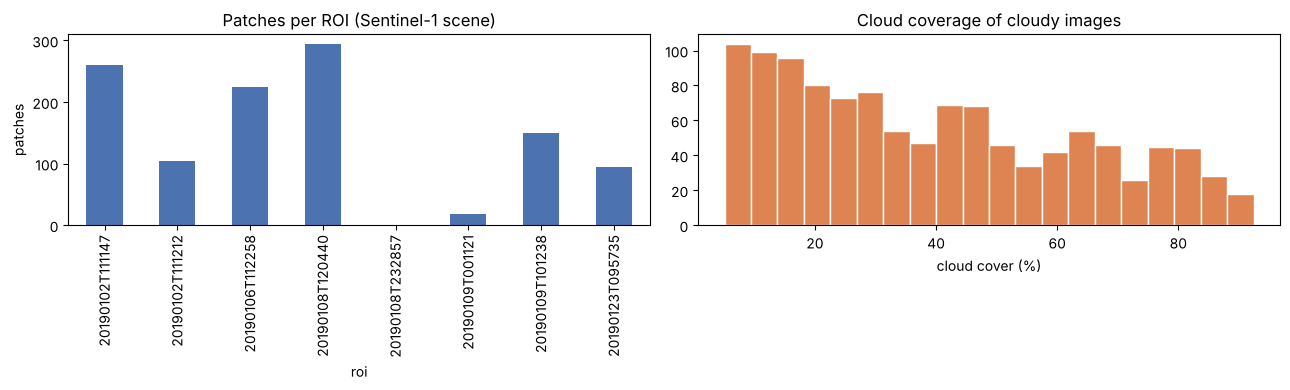

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
meta.groupby("roi").size().plot.bar(ax=ax[0], color="#4C72B0"); ax[0].set_title("Patches per ROI (Sentinel-1 scene)"); ax[0].set_ylabel("patches")
ax[1].hist(meta.cloud_frac * 100, bins=20, color="#DD8452", edgecolor="white"); ax[1].set_title("Cloud coverage of cloudy images"); ax[1].set_xlabel("cloud cover (%)")
plt.tight_layout(); plt.savefig(os.path.join(EVAL_DIR, "eda_rois_cloudcover.png"), dpi=110); plt.show()

## 7. EDA – Geographic Distribution
Shows patch locations (lon/lat) to confirm the global spread of the ROIs.

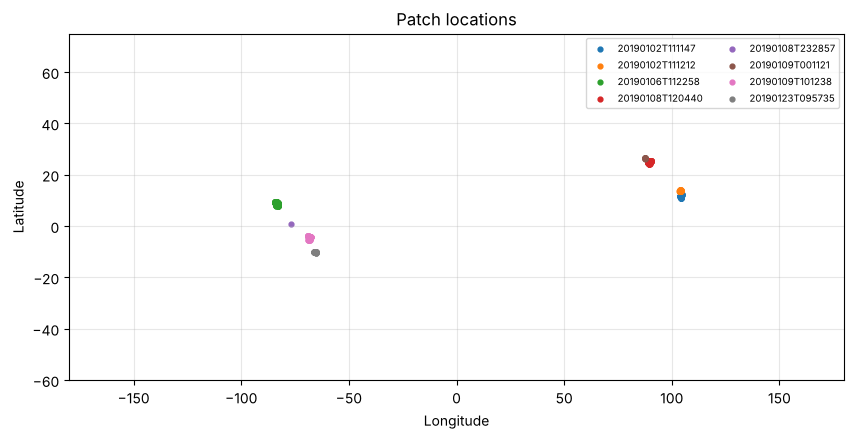

In [7]:
plt.figure(figsize=(10, 4.5))
for roi, g in meta.groupby("roi"): plt.scatter(g.lon, g.lat, s=12, label=roi)
plt.xlim(-180, 180); plt.ylim(-60, 75); plt.grid(alpha=.3); plt.xlabel("Longitude"); plt.ylabel("Latitude")
plt.legend(fontsize=7, ncol=2); plt.title("Patch locations"); plt.savefig(os.path.join(EVAL_DIR, "eda_locations.png"), dpi=110); plt.show()

## 8. EDA – Band Statistics (Sample)
Computes per-band mean reflectance of cloudy vs cloud-free images and SAR backscatter histograms on a random sample.

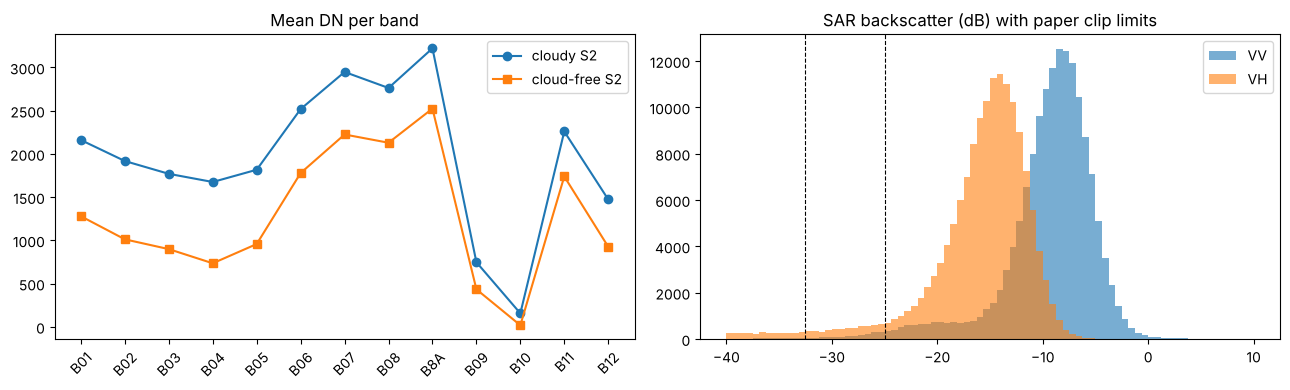

In [8]:
rng = np.random.default_rng(SEED)
sample = meta.patch.values[rng.permutation(len(meta))[:150]]
cl_m, cf_m, vv, vh = [], [], [], []
for n in sample:
    c, _ = read_tif(os.path.join(RAW_DIR, "s2_cloudy", n + ".tif")); f, _ = read_tif(os.path.join(RAW_DIR, "s2", n + ".tif")); s, _ = read_tif(os.path.join(RAW_DIR, "s1", n + ".tif"))
    cl_m.append(c.reshape(13, -1).mean(1)); cf_m.append(f.reshape(13, -1).mean(1)); vv.append(s[0, ::8, ::8].ravel()); vh.append(s[1, ::8, ::8].ravel())
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(BANDS, np.mean(cl_m, 0), "o-", label="cloudy S2"); ax[0].plot(BANDS, np.mean(cf_m, 0), "s-", label="cloud-free S2")
ax[0].set_title("Mean DN per band"); ax[0].legend(); ax[0].tick_params(axis="x", rotation=45)
ax[1].hist(np.concatenate(vv), bins=80, alpha=.6, label="VV", range=(-40, 10)); ax[1].hist(np.concatenate(vh), bins=80, alpha=.6, label="VH", range=(-40, 10))
for v in (-25, -32.5): ax[1].axvline(v, ls="--", c="k", lw=.8)
ax[1].set_title("SAR backscatter (dB) with paper clip limits"); ax[1].legend()
plt.tight_layout(); plt.savefig(os.path.join(EVAL_DIR, "eda_band_stats.png"), dpi=110); plt.show()

## 9. Define Rule-Based Cloud Detector
Implements the rule-based cloud detection used to create cloud masks (Schmitt et al. 2019, SEN12MS-CR toolbox), as required by PSF-CR.

In [9]:
def cloud_score(dn, cfg=PREPROC):
    d = dn.astype("float32") / 10000.0
    r = lambda x, lo_hi: (x - lo_hi[0]) / (lo_hi[1] - lo_hi[0])
    R = cfg["cloud_rules"]; s = np.ones(d.shape[1:], "float32")
    s = np.minimum(s, r(d[1], R["B02"])); s = np.minimum(s, r(d[0], R["B01"]))
    s = np.minimum(s, r(d[0] + d[10], R["B01+B10"])); s = np.minimum(s, r(d[3] + d[2] + d[1], R["B02+B03+B04"]))
    ndsi = (d[2] - d[11]) / (d[2] + d[11] + 1e-6); s = np.minimum(s, r(ndsi, R["NDSI(B03,B11)"]))
    k = cfg["cloud_closing_size"]; b = cfg["cloud_box_size"]
    s = ndimage.grey_closing(s, size=(k, k)); s = signal.convolve2d(s, np.ones((b, b)) / b ** 2, mode="same")
    return np.clip(s, 1e-5, 1.0)

def cloud_mask(dn, cfg=PREPROC):
    return (cloud_score(dn, cfg) >= cfg["cloud_threshold"]).astype("float32")

## 10. EDA – Visualise Triplets and Cloud Masks
Displays SAR, cloudy RGB, cloud mask and cloud-free RGB for four random patches.

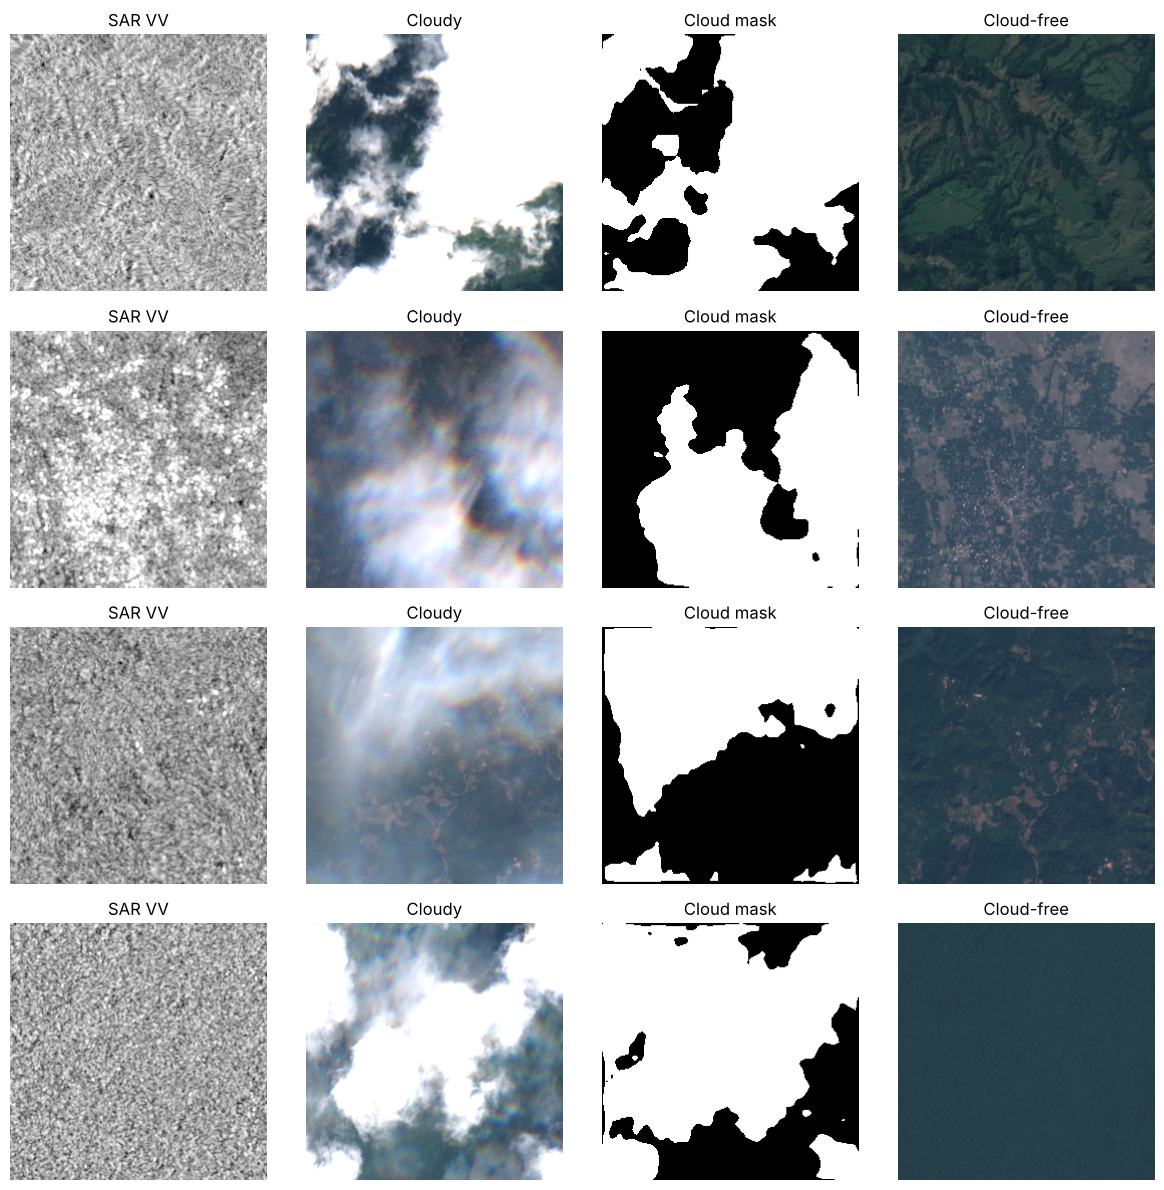

In [10]:
def rgb(dn): return np.clip(dn[[3, 2, 1]].transpose(1, 2, 0) / 3000.0, 0, 1)
fig, ax = plt.subplots(4, 4, figsize=(12, 12))
for i, n in enumerate(sample[:4]):
    s, _ = read_tif(os.path.join(RAW_DIR, "s1", n + ".tif")); c, _ = read_tif(os.path.join(RAW_DIR, "s2_cloudy", n + ".tif")); f, _ = read_tif(os.path.join(RAW_DIR, "s2", n + ".tif"))
    for j, (img, t) in enumerate([(np.clip((s[0] + 25) / 25, 0, 1), "SAR VV"), (rgb(c), "Cloudy"), (cloud_mask(c), "Cloud mask"), (rgb(f), "Cloud-free")]):
        ax[i, j].imshow(img, cmap="gray" if img.ndim == 2 else None); ax[i, j].set_title(t); ax[i, j].axis("off")
plt.tight_layout(); plt.savefig(os.path.join(EVAL_DIR, "eda_triplets.png"), dpi=100); plt.show()

## 11. Data Cleaning
Checks every triplet for missing files, NaN/Inf, nodata pixels, duplicates and cloud contamination of the target; removes invalid samples.

In [11]:
bad = []
for n in meta.patch:
    paths = [os.path.join(RAW_DIR, d, n + ".tif") for d in ("s1", "s2_cloudy", "s2")]
    if not all(os.path.exists(p) for p in paths): bad.append((n, "missing")); continue
    s, _ = read_tif(paths[0]); c, _ = read_tif(paths[1]); f, _ = read_tif(paths[2])
    if not np.isfinite(s).all(): bad.append((n, "nan_sar")); continue
    if (c == 0).any() or (f == 0).any(): bad.append((n, "nodata_s2")); continue
    if cloud_mask(f).mean() > 0.02: bad.append((n, "cloudy_target")); continue
dups = meta.patch.duplicated().sum()
print("invalid:", len(bad), pd.Series([b[1] for b in bad]).value_counts().to_dict() if bad else {}, "| duplicate ids:", dups)
meta = meta[~meta.patch.isin([b[0] for b in bad])].drop_duplicates("patch").reset_index(drop=True)
print("clean patches:", len(meta))

invalid: 0 {} | duplicate ids: 0
clean patches: 1149


## 12. Geospatially Separated Train / Validation / Test Split
Splits by ROI (whole Sentinel-1 scenes) so that test regions are never seen in training, avoiding spatial leakage (paper uses geospatially separated test ROIs).

In [12]:
roi_counts = meta.groupby("roi").size().sort_values()
rois = list(roi_counts.index)
rng = np.random.default_rng(SEED); rng.shuffle(rois)
test_rois, val_rois, n_test, n_val = [], [], 0, 0
N = len(meta)
for r in rois:   # greedily assign whole ROIs: ~20 % test, ~10 % validation, rest training
    c = roi_counts[r]
    if n_test < 0.2 * N and n_test + c <= 0.3 * N: test_rois.append(r); n_test += c
    elif n_val < 0.1 * N and n_val + c <= 0.2 * N: val_rois.append(r); n_val += c
meta["split"] = np.where(meta.roi.isin(test_rois), "test", np.where(meta.roi.isin(val_rois), "val", "train"))
print(meta.split.value_counts().to_dict()); print("test ROIs:", test_rois, "| val ROIs:", val_rois)
assert not set(meta[meta.split == "train"].roi) & set(meta[meta.split == "test"].roi)

{'train': 781, 'test': 254, 'val': 114}
test ROIs: ['20190102T111212', '20190109T101238'] | val ROIs: ['20190123T095735', '20190109T001121', '20190108T232857']


## 13. Preprocessing Function
Applies the paper's normalisation: SAR VV/VH clipped to [-25,0]/[-32.5,0] dB and scaled to [0,1]; S2 clipped to [0,10000] and scaled to [0,1]; cloud mask from the cloudy image.

In [13]:
def preprocess(s1_db, s2_cloudy_dn, s2_clear_dn=None, cfg=PREPROC):
    lo = np.array([cfg["s1_clip_db"][b][0] for b in cfg["s1_bands"]], "float32")[:, None, None]
    hi = np.array([cfg["s1_clip_db"][b][1] for b in cfg["s1_bands"]], "float32")[:, None, None]
    sar = (np.clip(s1_db, lo, hi) - lo) / (hi - lo)
    a, b = cfg["s2_clip"]
    opt = (np.clip(s2_cloudy_dn.astype("float32"), a, b) - a) / (b - a)
    mask = cloud_mask(s2_cloudy_dn, cfg)[None]
    tgt = None if s2_clear_dn is None else (np.clip(s2_clear_dn.astype("float32"), a, b) - a) / (b - a)
    return sar.astype("float32"), opt.astype("float32"), mask.astype("float32"), tgt

## 14. Preprocess and Cache All Splits
Preprocesses every triplet once and stores each split as float16 arrays in `data/processed/` for fast training.

In [14]:
def build_cache(split):
    names = meta[meta.split == split].patch.values; N = len(names); P = PREPROC["patch_size"]
    paths = {k: os.path.join(PROC_DIR, f"{split}_{k}.npy") for k in ("sar", "opt", "mask", "tgt")}
    arrs = {k: np.lib.format.open_memmap(paths[k], mode="w+", dtype="float16", shape=(N, c, P, P)) for k, c in (("sar", 2), ("opt", 13), ("mask", 1), ("tgt", 13))}
    for i, n in enumerate(names):
        s, _ = read_tif(os.path.join(RAW_DIR, "s1", n + ".tif")); c, _ = read_tif(os.path.join(RAW_DIR, "s2_cloudy", n + ".tif")); f, _ = read_tif(os.path.join(RAW_DIR, "s2", n + ".tif"))
        sar, opt, m, tgt = preprocess(s, c, f)
        arrs["sar"][i], arrs["opt"][i], arrs["mask"][i], arrs["tgt"][i] = sar, opt, m, tgt
    for a in arrs.values(): a.flush()
    meta[meta.split == split].to_csv(os.path.join(PROC_DIR, f"{split}_index.csv"), index=False)
    return N
t0 = time.time()
for sp in ("train", "val", "test"): print(sp, build_cache(sp), "patches cached")
print(f"done in {time.time() - t0:.0f}s")

train 781 patches cached


val 114 patches cached


test 254 patches cached
done in 73s


## 15. Feature Engineering – Cloud Mask Prior
Inspects the engineered cloud-mask feature (paper's prior for CMGR) and the cloudy/clear reflectance gap inside vs outside clouds on the training set.

In [15]:
tr = {k: np.load(os.path.join(PROC_DIR, f"train_{k}.npy"), mmap_mode="r") for k in ("opt", "mask", "tgt")}
idx = np.random.default_rng(SEED).permutation(len(tr["opt"]))[:100]
o, m, t = (np.asarray(tr[k][idx], dtype="float32") for k in ("opt", "mask", "tgt"))
diff = np.abs(o - t).mean(1, keepdims=True)
print(f"mean cloud fraction (train sample): {m.mean():.3f}")
print(f"|cloudy - clear| inside clouds: {diff[m > .5].mean():.4f} | outside clouds: {diff[m < .5].mean():.4f}")
print("All 13 Sentinel-2 bands + VV/VH are kept, as in the paper (no feature removal needed).")

mean cloud fraction (train sample): 0.393
|cloudy - clear| inside clouds: 0.1543 | outside clouds: 0.0352
All 13 Sentinel-2 bands + VV/VH are kept, as in the paper (no feature removal needed).


## 16. PyTorch Dataset and DataLoaders
Wraps cached arrays in a Dataset with random crops + flips/rotations for training and full 256×256 patches for validation/testing.

In [16]:
class CRDataset(Dataset):
    def __init__(self, split, crop=None, augment=False):
        self.a = {k: np.load(os.path.join(PROC_DIR, f"{split}_{k}.npy"), mmap_mode="r") for k in ("sar", "opt", "mask", "tgt")}
        self.crop, self.augment = crop, augment
    def __len__(self): return len(self.a["opt"])
    def __getitem__(self, i):
        x = [np.asarray(self.a[k][i], dtype="float32") for k in ("sar", "opt", "mask", "tgt")]
        if self.crop:
            P = x[0].shape[-1]; r, c = np.random.randint(0, P - self.crop + 1, 2)
            x = [v[:, r:r + self.crop, c:c + self.crop] for v in x]
        if self.augment:
            k = np.random.randint(4); fl = np.random.rand() < .5
            x = [np.rot90(v, k, (1, 2)) for v in x]; x = [v[:, :, ::-1] if fl else v for v in x]
        return [torch.from_numpy(np.ascontiguousarray(v)) for v in x]

train_ds = CRDataset("train", TRAIN_CFG["crop"], True); val_ds = CRDataset("val"); test_ds = CRDataset("test")
train_dl = DataLoader(train_ds, TRAIN_CFG["batch_size"], shuffle=True, drop_last=True, num_workers=0)
# fixed validation subset (full 256x256 patches) for per-epoch model selection on CPU
val_idx = np.random.default_rng(SEED).permutation(len(val_ds))[:TRAIN_CFG["n_val_monitor"]]
val_dl = DataLoader(torch.utils.data.Subset(val_ds, val_idx), 4); test_dl = DataLoader(test_ds, 4)
print("train", len(train_ds), "| val", len(val_ds), f"(monitor subset {len(val_idx)})", "| test", len(test_ds))

train 781 | val 114 (monitor subset 40) | test 254


## 17. Shared Building Blocks
Layer norm, window partitioning, frequency-domain filtering (`Conv3x3(ReLU(Conv1x1(·)))` on real/imag parts) and FFN used by all attention modules.

In [17]:
class LayerNorm2d(nn.Module):
    def __init__(s, c):
        super().__init__(); s.w = nn.Parameter(torch.ones(c)); s.b = nn.Parameter(torch.zeros(c))
    def forward(s, x):
        mu = x.mean(1, keepdim=True); var = (x - mu).pow(2).mean(1, keepdim=True)
        return (x - mu) / torch.sqrt(var + 1e-6) * s.w[:, None, None] + s.b[:, None, None]

def window_partition(x, ws):
    B, C, H, W = x.shape
    return x.view(B, C, H // ws, ws, W // ws, ws).permute(0, 2, 4, 3, 5, 1).reshape(-1, ws * ws, C)

def window_reverse(w, ws, B, C, H, W):
    return w.view(B, H // ws, W // ws, ws, ws, C).permute(0, 5, 1, 3, 2, 4).reshape(B, C, H, W)

class FreqFilter(nn.Module):
    def __init__(s, cin, cout):
        super().__init__(); s.f = nn.Sequential(nn.Conv2d(cin, cin, 1), nn.ReLU(inplace=True), nn.Conv2d(cin, cout, 3, padding=1))
    def forward(s, z):
        r, i = s.f(torch.cat([z.real, z.imag], 1)).chunk(2, 1)
        return torch.complex(r, i)

class FFN(nn.Module):
    def __init__(s, c, e=2):
        super().__init__(); s.n = nn.Sequential(nn.Conv2d(c, c * e, 1), nn.GELU(), nn.Conv2d(c * e, c * e, 3, padding=1, groups=c * e), nn.GELU(), nn.Conv2d(c * e, c, 1))
    def forward(s, x): return s.n(x)

## 18. PSF-CR Module – Frequency-Domain Global Cross-Alignment (FGCA)
Implements Algorithm 1 of the paper: FFT → filtering → joint cross-modal frequency filter → element-wise product → IFFT → softmax gating → fusion conv.

In [18]:
class FGCA(nn.Module):
    def __init__(s, c, gate="softmax"):
        super().__init__(); s.gate = gate
        s.fo, s.fs, s.ff = FreqFilter(2 * c, 2 * c), FreqFilter(2 * c, 2 * c), FreqFilter(4 * c, 2 * c)
        s.co, s.cs, s.out = nn.Conv2d(c, c, 1), nn.Conv2d(c, c, 1), nn.Conv2d(2 * c, c, 3, padding=1)
    def forward(s, fo, fs):
        H, W = fo.shape[-2:]
        zo = s.fo(torch.fft.rfft2(fo, norm="ortho")); zs = s.fs(torch.fft.rfft2(fs, norm="ortho"))
        zf = s.ff(torch.cat([zo, zs], 1))                       # F'_freq = Filtering(concat(F'_opt, F'_sar))
        so = torch.fft.irfft2(zf * zo, s=(H, W), norm="ortho")   # F'_opt = F'_freq ⊙ F'_opt
        ss = torch.fft.irfft2(zf * zs, s=(H, W), norm="ortho")
        if s.gate == "softmax":                                  # paper: Softmax(IFFT(Conv1x1)) ⊙ F' (spatial softmax, rescaled by N)
            n = float(H * W)
            so = torch.softmax(s.co(so).flatten(2), -1).view_as(so) * n * so
            ss = torch.softmax(s.cs(ss).flatten(2), -1).view_as(ss) * n * ss
        else:                                                    # PSF-CR++: un-gated projection (more stable, see ablation note)
            so, ss = s.co(so), s.cs(ss)
        return s.out(torch.cat([so, ss], 1))

## 19. PSF-CR Module – Spatial-Domain Local Cross-Alignment (SLCA)
8×8 window cross-attention with ConvPE; queries are exchanged between SAR and optical streams (Eqs. 1–2), followed by FFN and a 3×3 fusion conv.

In [19]:
class SLCA(nn.Module):
    def __init__(s, c, ws=8, heads=2):
        super().__init__(); s.ws, s.h = ws, heads
        s.pe_o, s.pe_s = nn.Conv2d(c, c, 3, padding=1, groups=c), nn.Conv2d(c, c, 3, padding=1, groups=c)
        s.qkv_o, s.qkv_s = nn.Conv2d(c, 3 * c, 1), nn.Conv2d(c, 3 * c, 1)
        s.ffn_o, s.ffn_s, s.n_o, s.n_s = FFN(c), FFN(c), LayerNorm2d(c), LayerNorm2d(c)
        s.out = nn.Conv2d(2 * c, c, 3, padding=1)
    def attn(s, q, k, v, B, C, H, W):
        q, k, v = [window_partition(t, s.ws) for t in (q, k, v)]
        n, L, _ = q.shape; d = C // s.h
        q, k, v = [t.view(n, L, s.h, d).transpose(1, 2) for t in (q, k, v)]
        a = torch.softmax(q @ k.transpose(-2, -1) / math.sqrt(d), -1) @ v
        return window_reverse(a.transpose(1, 2).reshape(n, L, C), s.ws, B, C, H, W)
    def forward(s, fo, fs):
        B, C, H, W = fo.shape
        fo = fo + s.pe_o(fo); fs = fs + s.pe_s(fs)
        qo, ko, vo = s.qkv_o(fo).chunk(3, 1); qs, ks, vs = s.qkv_s(fs).chunk(3, 1)
        co = fo + s.attn(qs, ko, vo, B, C, H, W)   # CA_opt = softmax(Q_sar K_opt^T / sqrt(d)) V_opt
        cs = fs + s.attn(qo, ks, vs, B, C, H, W)   # CA_sar = softmax(Q_opt K_sar^T / sqrt(d)) V_sar
        co = co + s.ffn_o(s.n_o(co)); cs = cs + s.ffn_s(s.n_s(cs))
        return s.out(torch.cat([co, cs], 1))

class SFFA(nn.Module):
    """Joint spatial-frequency feature alignment = concat(FGCA, SLCA)."""
    def __init__(s, c, ws=8, gate="softmax"):
        super().__init__(); s.g, s.l, s.fuse = FGCA(c, gate), SLCA(c, ws), nn.Conv2d(2 * c, c, 1)
    def forward(s, fo, fs): return s.fuse(torch.cat([s.g(fo, fs), s.l(fo, fs)], 1))

## 20. PSF-CR Module – Cloud-Mask-Guided Rectification (CMGR)
Soft gating: sigmoid(mask feature) ⊙ F_opt / F_sar → concat → conv + LayerNorm + sigmoid = weight matrix W; output W·F_fuse + F_fuse.

In [20]:
class CMGR(nn.Module):
    def __init__(s, c):
        super().__init__(); s.m = nn.Conv2d(1, c, 3, padding=1); s.w = nn.Conv2d(2 * c, c, 3, padding=1); s.ln = LayerNorm2d(c)
    def forward(s, mask, fo, fs, ffuse):
        fm = torch.sigmoid(s.m(mask))
        W = torch.sigmoid(s.ln(s.w(torch.cat([fm * fo, fm * fs], 1))))
        return W * ffuse + ffuse, W

## 21. PSF-CR Module – Reconstruction Blocks (MCL, SLSA, FGSA)
Multi-scale conv layer, window self-attention with parallel conv branch, and frequency-domain global self-attention; one reconstruction block = MCL → SLSA → FGSA.

In [21]:
class MCL(nn.Module):
    def __init__(s, c):
        super().__init__()
        s.b1, s.b2, s.b3 = nn.Conv2d(c, c, 1), nn.Conv2d(c, c, 1), nn.Conv2d(c, c, 1)
        s.d2, s.d3 = nn.Conv2d(c, c, 3, padding=1, groups=c), nn.Conv2d(c, c, 3, padding=1, groups=c)
        s.out, s.n = nn.Conv2d(3 * c, c, 1), LayerNorm2d(c)
    def forward(s, x):
        y = s.n(x); a = s.b1(y); b = s.d2(s.b2(y) + a); c = s.d3(s.b3(y) + b)
        return x + s.out(F.gelu(torch.cat([a, b, c], 1)))

class SLSA(nn.Module):
    def __init__(s, c, ws=8, heads=2):
        super().__init__(); s.ws, s.h = ws, heads
        s.n, s.qkv, s.pe = LayerNorm2d(c), nn.Conv2d(c, 3 * c, 1), nn.Conv2d(c, c, 3, padding=1, groups=c)
        s.conv, s.proj = nn.Conv2d(c, c, 3, padding=1), nn.Conv2d(c, c, 1)
    def forward(s, x):
        B, C, H, W = x.shape; y = s.n(x); y = y + s.pe(y)
        q, k, v = [window_partition(t, s.ws) for t in s.qkv(y).chunk(3, 1)]
        n, L, _ = q.shape; d = C // s.h
        q, k, v = [t.view(n, L, s.h, d).transpose(1, 2) for t in (q, k, v)]
        a = torch.softmax(q @ k.transpose(-2, -1) / math.sqrt(d), -1) @ v
        a = window_reverse(a.transpose(1, 2).reshape(n, L, C), s.ws, B, C, H, W)
        return x + s.proj(a + s.conv(y))

class FGSA(nn.Module):
    def __init__(s, c, ffn=None, gate="softmax"):
        super().__init__(); s.gate = gate
        s.n, s.fq, s.fk = LayerNorm2d(c), FreqFilter(2 * c, 2 * c), FreqFilter(2 * c, 2 * c)
        s.v = nn.Sequential(nn.Conv2d(c, c, 1), nn.Conv2d(c, c, 3, padding=1, groups=c)); s.proj = nn.Conv2d(c, c, 1)
        s.n2, s.ffn = LayerNorm2d(c), (ffn if ffn is not None else FFN(c))
        s.na = LayerNorm2d(c) if gate != "softmax" else nn.Identity()
    def forward(s, x):
        H, W = x.shape[-2:]; y = s.n(x); z = torch.fft.rfft2(y, norm="ortho")
        a = torch.fft.irfft2(s.fq(z) * s.fk(z), s=(H, W), norm="ortho")       # global Q·K via element-wise product in frequency domain
        if s.gate == "softmax": a = torch.softmax(a.flatten(2), -1).view_as(a) * float(H * W)   # paper: softmax attention
        else: a = s.na(a)                                                                        # PSF-CR++: LayerNorm-normalised frequency attention (FSAS-style)
        x = x + s.proj(a * s.v(y))
        return x + s.ffn(s.n2(x))

class ReconBlock(nn.Module):
    def __init__(s, c, ws=8, ffn_cls=None, gate="softmax"):
        super().__init__(); s.b = nn.Sequential(MCL(c), SLSA(c, ws), FGSA(c, ffn_cls(c) if ffn_cls else None, gate))
    def forward(s, x): return s.b(x)

## 22. PSF-CR Full Network
Assembles SFFA → CMGR → five-stage U-shaped reconstruction (two 2× downsamplings, bottleneck, two upsamplings with skip connections). Returns the prediction and the CMGR weight map used by the weighted L1 loss.

In [22]:
class PSFCR(nn.Module):
    def __init__(s, opt_ch=13, sar_ch=2, c=32, ws=8, ffn_cls=None, extra_bottleneck=None, gate="softmax"):
        super().__init__()
        s.eo, s.es = nn.Conv2d(opt_ch, c, 3, padding=1), nn.Conv2d(sar_ch, c, 3, padding=1)
        s.sffa, s.cmgr = SFFA(c, ws, gate), CMGR(c)
        s.e1, s.d1 = ReconBlock(c, ws, ffn_cls, gate), nn.Conv2d(c, 2 * c, 4, 2, 1)
        s.e2, s.d2 = ReconBlock(2 * c, ws, ffn_cls, gate), nn.Conv2d(2 * c, 4 * c, 4, 2, 1)
        s.mid = ReconBlock(4 * c, ws, ffn_cls, gate)
        s.extra = extra_bottleneck(4 * c) if extra_bottleneck else nn.Identity()
        s.u2, s.r2, s.dec2 = nn.ConvTranspose2d(4 * c, 2 * c, 2, 2), nn.Conv2d(4 * c, 2 * c, 1), ReconBlock(2 * c, ws, ffn_cls, gate)
        s.u1, s.r1, s.dec1 = nn.ConvTranspose2d(2 * c, c, 2, 2), nn.Conv2d(2 * c, c, 1), ReconBlock(c, ws, ffn_cls, gate)
        s.head = nn.Conv2d(c, opt_ch, 3, padding=1)
    def features(s, sar, opt, mask):
        fo, fs = s.eo(opt), s.es(sar)
        f, Wm = s.cmgr(mask, fo, fs, s.sffa(fo, fs))
        x1 = s.e1(f); x2 = s.e2(s.d1(x1)); x3 = s.extra(s.mid(s.d2(x2)))
        y2 = s.dec2(s.r2(torch.cat([s.u2(x3), x2], 1)))
        y1 = s.dec1(s.r1(torch.cat([s.u1(y2), x1], 1)))
        return y1, Wm
    def forward(s, sar, opt, mask):
        y1, Wm = s.features(sar, opt, mask)
        return opt + s.head(y1), Wm.mean(1, keepdim=True)

## 23. Baseline – DSen2-CR
Existing baseline from the paper's comparison: early fusion of SAR + optical, residual ResNet with long skip from the cloudy input (feature width reduced for CPU training).

In [23]:
class DSen2CR(nn.Module):
    def __init__(s, opt_ch=13, sar_ch=2, feats=64, blocks=8, scale=0.1):
        super().__init__(); s.scale = scale
        s.inp = nn.Conv2d(opt_ch + sar_ch, feats, 3, padding=1)
        s.blocks = nn.ModuleList([nn.Sequential(nn.Conv2d(feats, feats, 3, padding=1), nn.ReLU(inplace=True), nn.Conv2d(feats, feats, 3, padding=1)) for _ in range(blocks)])
        s.out = nn.Conv2d(feats, opt_ch, 3, padding=1)
    def forward(s, sar, opt, mask):
        x = F.relu(s.inp(torch.cat([opt, sar], 1)))
        for b in s.blocks: x = x + s.scale * b(x)
        return opt + s.out(x), None

## 24. Advanced Model – Restormer Components
Multi-Dconv-head Transposed Attention (global channel attention, linear in image size) and Gated-Dconv FFN from Restormer (CVPR 2022).

In [24]:
class MDTA(nn.Module):
    def __init__(s, c, heads=2):
        super().__init__(); s.h = heads; s.t = nn.Parameter(torch.ones(heads, 1, 1))
        s.qkv = nn.Conv2d(c, 3 * c, 1); s.dw = nn.Conv2d(3 * c, 3 * c, 3, padding=1, groups=3 * c); s.p = nn.Conv2d(c, c, 1)
    def forward(s, x):
        B, C, H, W = x.shape
        q, k, v = [t.reshape(B, s.h, C // s.h, H * W) for t in s.dw(s.qkv(x)).chunk(3, 1)]
        a = torch.softmax(F.normalize(q, dim=-1) @ F.normalize(k, dim=-1).transpose(-2, -1) * s.t, -1)
        return s.p((a @ v).reshape(B, C, H, W))

class GDFN(nn.Module):
    def __init__(s, c, e=2.0):
        super().__init__(); h = int(c * e)
        s.i = nn.Conv2d(c, 2 * h, 1); s.dw = nn.Conv2d(2 * h, 2 * h, 3, padding=1, groups=2 * h); s.o = nn.Conv2d(h, c, 1)
    def forward(s, x):
        a, b = s.dw(s.i(x)).chunk(2, 1); return s.o(F.gelu(a) * b)

class RestormerBlock(nn.Module):
    def __init__(s, c, heads=2):
        super().__init__(); s.n1, s.a, s.n2, s.f = LayerNorm2d(c), MDTA(c, heads), LayerNorm2d(c), GDFN(c)
    def forward(s, x):
        x = x + s.a(s.n1(x)); return x + s.f(s.n2(x))

## 25. Advanced Model – Restormer-CR
Mask-guided Restormer U-Net: SAR, cloudy optical and cloud mask are fused at the input; output is a residual correction of the cloudy image.

In [25]:
class RestormerCR(nn.Module):
    def __init__(s, opt_ch=13, sar_ch=2, c=32, nb=(2, 2, 4)):
        super().__init__()
        s.inp = nn.Conv2d(opt_ch + sar_ch + 1, c, 3, padding=1)
        s.e1 = nn.Sequential(*[RestormerBlock(c, 1) for _ in range(nb[0])]); s.d1 = nn.Conv2d(c, 2 * c, 4, 2, 1)
        s.e2 = nn.Sequential(*[RestormerBlock(2 * c, 2) for _ in range(nb[1])]); s.d2 = nn.Conv2d(2 * c, 4 * c, 4, 2, 1)
        s.mid = nn.Sequential(*[RestormerBlock(4 * c, 4) for _ in range(nb[2])])
        s.u2, s.r2 = nn.ConvTranspose2d(4 * c, 2 * c, 2, 2), nn.Conv2d(4 * c, 2 * c, 1); s.dec2 = nn.Sequential(*[RestormerBlock(2 * c, 2) for _ in range(nb[1])])
        s.u1, s.r1 = nn.ConvTranspose2d(2 * c, c, 2, 2), nn.Conv2d(2 * c, c, 1); s.dec1 = nn.Sequential(*[RestormerBlock(c, 1) for _ in range(nb[0])])
        s.head = nn.Conv2d(c, opt_ch, 3, padding=1)
    def forward(s, sar, opt, mask):
        x1 = s.e1(s.inp(torch.cat([opt, sar, mask], 1))); x2 = s.e2(s.d1(x1)); x3 = s.mid(s.d2(x2))
        y2 = s.dec2(s.r2(torch.cat([s.u2(x3), x2], 1))); y1 = s.dec1(s.r1(torch.cat([s.u1(y2), x1], 1)))
        return opt + s.head(y1), None

## 26. Proposed Advanced Model – PSF-CR++
PSF-CR backbone upgraded with (i) LayerNorm-normalised frequency attention (FSAS-style) instead of the N-scaled spatial softmax, which trained faster in a pilot run on this data, (ii) gated-Dconv FFNs in every FGSA block, (iii) two transposed-attention (MDTA) blocks in the bottleneck for global channel interaction, and (iv) a mask-aware adaptive output fusion α·restored + (1−α)·cloudy.

In [26]:
class PSFCRPlus(nn.Module):
    def __init__(s, opt_ch=13, sar_ch=2, c=32, ws=8):
        super().__init__()
        s.net = PSFCR(opt_ch, sar_ch, c, ws, ffn_cls=lambda ch: GDFN(ch, 1.5), gate="norm",
                      extra_bottleneck=lambda ch: nn.Sequential(RestormerBlock(ch, 4), RestormerBlock(ch, 4)))
        s.alpha = nn.Sequential(nn.Conv2d(c + 1, c, 3, padding=1), nn.GELU(), nn.Conv2d(c, 1, 3, padding=1))
        nn.init.zeros_(s.alpha[2].weight); nn.init.constant_(s.alpha[2].bias, 3.0)   # start with α≈0.95 (trust the restoration), learn where to keep input pixels
    def forward(s, sar, opt, mask):
        y1, Wm = s.net.features(sar, opt, mask)
        restored = opt + s.net.head(y1)
        a = torch.sigmoid(s.alpha(torch.cat([y1, mask], 1)))   # mask-aware per-pixel fusion weight
        return a * restored + (1 - a) * opt, Wm.mean(1, keepdim=True)

## 27. Model Registry
Lists all models with their constructor arguments; the residual output head of every model is zero-initialised (training starts from the cloudy input). Prints parameter counts.

In [27]:
MODEL_SPECS = {
    "dsen2cr":      {"cls": "DSen2CR",     "kwargs": {"feats": 64, "blocks": 8}, "display": "DSen2-CR"},
    "psfcr":        {"cls": "PSFCR",       "kwargs": {"c": 32, "ws": 8},        "display": "PSF-CR (paper)"},
    "restormer_cr": {"cls": "RestormerCR", "kwargs": {"c": 32},                 "display": "Restormer-CR"},
    "psfcr_plus":   {"cls": "PSFCRPlus",   "kwargs": {"c": 32, "ws": 8},        "display": "PSF-CR++ (proposed)"},
}
def build_model(key):
    spec = MODEL_SPECS[key]; m = globals()[spec["cls"]](**spec["kwargs"])
    head = m.net.head if hasattr(m, "net") else (m.out if isinstance(m, DSen2CR) else m.head)
    nn.init.zeros_(head.weight); nn.init.zeros_(head.bias)   # residual head starts at zero -> identity mapping of the cloudy input
    return m
for k in MODEL_SPECS:
    m = build_model(k); print(f"{MODEL_SPECS[k]['display']:22s} params = {sum(p.numel() for p in m.parameters()) / 1e6:.3f} M")

DSen2-CR               params = 0.607 M
PSF-CR (paper)         params = 3.297 M
Restormer-CR           params = 1.158 M
PSF-CR++ (proposed)    params = 3.673 M


## 28. Composite Spatial-Frequency Loss
Paper Eqs. (3)–(7): L = λ1·(weighted L1 + α(1−SSIM)) + λ2·(L1 on FFT real + L1 on FFT imag + spectral convergence). The weighted L1 uses the CMGR weight map (1 + W) to emphasise cloud regions.

In [28]:
def composite_loss(pred, tgt, W=None, cfg=TRAIN_CFG):
    w = torch.ones_like(pred[:, :1]) if W is None else (1.0 + W.detach())
    l1w = (w * (pred - tgt).abs()).sum() / (w.sum() * pred.shape[1])
    l_ssim = 1 - ssim_fn(pred.clamp(0, 1), tgt, data_range=1.0, win_size=11, size_average=True)
    l_spa = l1w + cfg["alpha_ssim"] * l_ssim
    fp, ft = torch.fft.fft2(pred, norm="ortho"), torch.fft.fft2(tgt, norm="ortho")
    sc = torch.linalg.vector_norm((fp - ft).abs().flatten(1), dim=1) / (torch.linalg.vector_norm(ft.abs().flatten(1), dim=1) + 1e-8)
    l_freq = (fp.real - ft.real).abs().mean() + (fp.imag - ft.imag).abs().mean() + sc.mean()
    return cfg["lambda_spa"] * l_spa + cfg["lambda_freq"] * l_freq

## 29. Evaluation Metrics
PSNR, SSIM, SAM (degrees) and MAE computed per image on [0,1] reflectance, plus optional region masks (cloud / cloud-free).

In [29]:
def psnr(p, t, region=None):
    se = (p - t) ** 2
    mse = se.mean((1, 2, 3)) if region is None else (se * region).sum((1, 2, 3)) / (region.sum((1, 2, 3)) * p.shape[1]).clamp(min=1)
    return 10 * torch.log10(1.0 / mse.clamp(min=1e-10))

def sam(p, t, region=None):
    cos = (p * t).sum(1) / (p.norm(dim=1) * t.norm(dim=1) + 1e-8)
    ang = torch.rad2deg(torch.acos(cos.clamp(-1, 1)))
    return ang.mean((1, 2)) if region is None else (ang * region[:, 0]).sum((1, 2)) / region[:, 0].sum((1, 2)).clamp(min=1)

def mae(p, t, region=None):
    ae = (p - t).abs()
    return ae.mean((1, 2, 3)) if region is None else (ae * region).sum((1, 2, 3)) / (region.sum((1, 2, 3)) * p.shape[1]).clamp(min=1)

def ssim_img(p, t): return ssim_fn(p, t, data_range=1.0, win_size=11, size_average=False)

## 30. Training and Validation Functions
Adam (β=0.9/0.999, weight decay 1e-4) with cosine annealing 2e-4 → 2e-6 as in the paper; keeps the checkpoint with the best validation PSNR.

In [30]:
@torch.no_grad()
def evaluate(model, dl, per_image=False):
    """Single inference pass: global PSNR/SSIM/SAM/MAE, cloud vs clear region metrics, per-band PSNR and cloud cover."""
    model.eval(); recs = []
    for sar, opt, mask, tgt in dl:
        sar, opt, mask, tgt = (v.to(DEVICE) for v in (sar, opt, mask, tgt))
        p = model(sar, opt, mask)[0].clamp(0, 1)
        g = {"PSNR": psnr(p, tgt), "SSIM": ssim_img(p, tgt), "SAM": sam(p, tgt), "MAE": mae(p, tgt), "cloud_cover": mask.mean((1, 2, 3))}
        if per_image:
            for r, reg in (("cloud", mask), ("clear", 1 - mask)):
                g[f"PSNR_{r}"], g[f"SAM_{r}"], g[f"MAE_{r}"] = psnr(p, tgt, reg), sam(p, tgt, reg), mae(p, tgt, reg)
                g[f"has_{r}"] = (reg.sum((1, 2, 3)) > 0).float()
            band_psnr = 10 * torch.log10(1 / ((p - tgt) ** 2).mean((2, 3)).clamp(min=1e-10))
            for b in range(band_psnr.shape[1]): g[f"PSNR_{BANDS[b]}"] = band_psnr[:, b]
        for i in range(len(p)): recs.append({k: float(v[i]) for k, v in g.items()})
    df = pd.DataFrame(recs)
    return df if per_image else {k: float(df[k].mean()) for k in ("PSNR", "SSIM", "SAM", "MAE")}

def train_model(key, cfg=TRAIN_CFG):
    torch.manual_seed(SEED); np.random.seed(SEED)
    model = build_model(key).to(DEVICE)
    opt_ = torch.optim.Adam(model.parameters(), lr=cfg["lr"], betas=cfg["betas"], weight_decay=cfg["weight_decay"])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt_, T_max=cfg["epochs"] * len(train_dl), eta_min=cfg["lr_min"])
    out_dir = os.path.join(MODEL_DIR, key); os.makedirs(out_dir, exist_ok=True)
    hist, best, t0 = [], -1e9, time.time()
    for ep in range(1, cfg["epochs"] + 1):
        model.train(); losses = []
        for sar, opt, mask, tgt in train_dl:
            sar, opt, mask, tgt = (v.to(DEVICE) for v in (sar, opt, mask, tgt))
            pred, W = model(sar, opt, mask)
            loss = composite_loss(pred, tgt, W)
            opt_.zero_grad(); loss.backward(); torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt_.step(); sched.step()
            losses.append(loss.item())
        v = evaluate(model, val_dl)
        hist.append({"epoch": ep, "train_loss": float(np.mean(losses)), **{f"val_{k}": x for k, x in v.items()}, "time_s": time.time() - t0})
        if ep == 1 or v["PSNR"] > best:
            best = v["PSNR"]; torch.save(model.state_dict(), os.path.join(out_dir, f"{key}.pth"))
        print(f"[{key}] ep {ep:02d} loss {hist[-1]['train_loss']:.4f} | val PSNR {v['PSNR']:.2f} SSIM {v['SSIM']:.4f} SAM {v['SAM']:.2f} MAE {v['MAE']:.4f} | {time.time() - t0:.0f}s", flush=True)
    pd.DataFrame(hist).to_csv(os.path.join(out_dir, "training_history.csv"), index=False)
    cfg_out = {"model_key": key, **MODEL_SPECS[key], "train_cfg": {k: list(v) if isinstance(v, tuple) else v for k, v in cfg.items()},
               "best_val_psnr": best, "n_params": sum(p.numel() for p in model.parameters()), "train_time_s": time.time() - t0}
    json.dump(cfg_out, open(os.path.join(out_dir, "model_config.json"), "w"), indent=2)
    json.dump(PREPROC, open(os.path.join(out_dir, "preprocessing.json"), "w"), indent=2)
    model.load_state_dict(torch.load(os.path.join(out_dir, f"{key}.pth"), map_location=DEVICE))
    return model, pd.DataFrame(hist)

trained, histories = {}, {}

## 31. Evaluate the Cloudy Input (Reference Lower Bound)
Scores the unprocessed cloudy image against the cloud-free target to give a no-model reference point.

In [31]:
class Identity(nn.Module):
    def forward(s, sar, opt, mask): return opt, None
ref_val = evaluate(Identity(), DataLoader(val_ds, 4)); ref_test_df = evaluate(Identity(), test_dl, per_image=True)
ref_test = {k: float(ref_test_df[k].mean()) for k in ("PSNR", "SSIM", "SAM", "MAE")}
print("cloudy input  val:", {k: round(v, 4) for k, v in ref_val.items()}); print("cloudy input test:", {k: round(v, 4) for k, v in ref_test.items()})

cloudy input  val: {'PSNR': 22.3493, 'SSIM': 0.7487, 'SAM': 11.0088, 'MAE': 0.0614}
cloudy input test: {'PSNR': 20.9141, 'SSIM': 0.7366, 'SAM': 12.7128, 'MAE': 0.0784}


## 32. Train DSen2-CR (Baseline)
Trains `dsen2cr` with the composite loss and saves its best checkpoint to `models/dsen2cr/`.

In [32]:
trained["dsen2cr"], histories["dsen2cr"] = train_model("dsen2cr")

[dsen2cr] ep 01 loss 0.0941 | val PSNR 27.72 SSIM 0.8358 SAM 9.42 MAE 0.0325 | 298s


[dsen2cr] ep 02 loss 0.0710 | val PSNR 27.17 SSIM 0.8472 SAM 7.89 MAE 0.0326 | 595s


[dsen2cr] ep 03 loss 0.0627 | val PSNR 28.78 SSIM 0.8548 SAM 7.62 MAE 0.0274 | 903s


[dsen2cr] ep 04 loss 0.0590 | val PSNR 28.91 SSIM 0.8626 SAM 7.19 MAE 0.0267 | 1193s


[dsen2cr] ep 05 loss 0.0567 | val PSNR 28.26 SSIM 0.8630 SAM 6.99 MAE 0.0285 | 1490s


[dsen2cr] ep 06 loss 0.0563 | val PSNR 28.45 SSIM 0.8610 SAM 6.97 MAE 0.0279 | 1782s


## 33. Train PSF-CR (Paper Method)
Trains `psfcr` with the composite loss and saves its best checkpoint to `models/psfcr/`.

In [33]:
trained["psfcr"], histories["psfcr"] = train_model("psfcr")

[psfcr] ep 01 loss 0.1104 | val PSNR 24.50 SSIM 0.7442 SAM 12.30 MAE 0.0479 | 572s


[psfcr] ep 02 loss 0.0863 | val PSNR 26.34 SSIM 0.8179 SAM 8.83 MAE 0.0369 | 1113s


[psfcr] ep 03 loss 0.0778 | val PSNR 27.54 SSIM 0.8350 SAM 8.75 MAE 0.0315 | 1635s


[psfcr] ep 04 loss 0.0698 | val PSNR 27.59 SSIM 0.8398 SAM 8.23 MAE 0.0311 | 2164s


[psfcr] ep 05 loss 0.0643 | val PSNR 27.87 SSIM 0.8469 SAM 7.58 MAE 0.0298 | 2718s


[psfcr] ep 06 loss 0.0631 | val PSNR 27.92 SSIM 0.8465 SAM 7.56 MAE 0.0297 | 3318s


## 34. Train Restormer-CR (Advanced)
Trains `restormer_cr` with the composite loss and saves its best checkpoint to `models/restormer_cr/`.

In [34]:
trained["restormer_cr"], histories["restormer_cr"] = train_model("restormer_cr")

[restormer_cr] ep 01 loss 0.1020 | val PSNR 28.15 SSIM 0.8441 SAM 8.87 MAE 0.0298 | 334s


[restormer_cr] ep 02 loss 0.0737 | val PSNR 27.93 SSIM 0.8528 SAM 8.18 MAE 0.0294 | 671s


[restormer_cr] ep 03 loss 0.0673 | val PSNR 27.91 SSIM 0.8504 SAM 7.81 MAE 0.0296 | 1013s


[restormer_cr] ep 04 loss 0.0634 | val PSNR 27.58 SSIM 0.8467 SAM 7.73 MAE 0.0308 | 1364s


[restormer_cr] ep 05 loss 0.0613 | val PSNR 28.12 SSIM 0.8524 SAM 7.72 MAE 0.0288 | 1708s


[restormer_cr] ep 06 loss 0.0608 | val PSNR 27.95 SSIM 0.8508 SAM 7.73 MAE 0.0294 | 2058s


## 35. Train PSF-CR++ (Proposed Advanced)
Trains `psfcr_plus` with the composite loss and saves its best checkpoint to `models/psfcr_plus/`.

In [35]:
trained["psfcr_plus"], histories["psfcr_plus"] = train_model("psfcr_plus")

[psfcr_plus] ep 01 loss 0.1154 | val PSNR 27.22 SSIM 0.8233 SAM 9.29 MAE 0.0328 | 632s


[psfcr_plus] ep 02 loss 0.0956 | val PSNR 28.01 SSIM 0.8424 SAM 9.00 MAE 0.0295 | 1239s


[psfcr_plus] ep 03 loss 0.0785 | val PSNR 27.48 SSIM 0.8394 SAM 8.03 MAE 0.0313 | 1889s


[psfcr_plus] ep 04 loss 0.0702 | val PSNR 27.50 SSIM 0.8296 SAM 8.25 MAE 0.0317 | 2527s


[psfcr_plus] ep 05 loss 0.0655 | val PSNR 28.14 SSIM 0.8393 SAM 7.62 MAE 0.0291 | 3157s


[psfcr_plus] ep 06 loss 0.0638 | val PSNR 28.14 SSIM 0.8359 SAM 7.63 MAE 0.0292 | 3773s


## 36. Training Curves
Plots training loss and validation PSNR per epoch for all models.

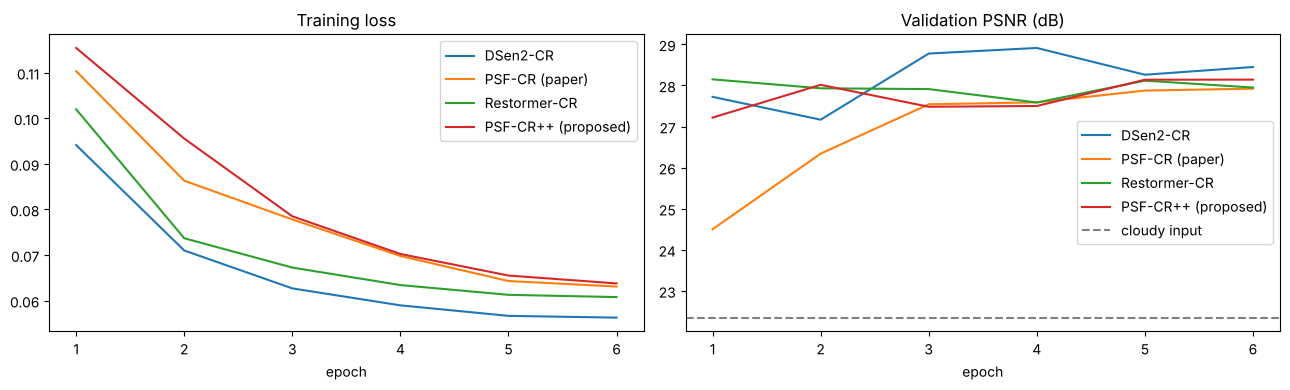

In [36]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for k, h in histories.items():
    ax[0].plot(h.epoch, h.train_loss, label=MODEL_SPECS[k]["display"]); ax[1].plot(h.epoch, h.val_PSNR, label=MODEL_SPECS[k]["display"])
ax[1].axhline(ref_val["PSNR"], ls="--", c="gray", label="cloudy input")
ax[0].set_title("Training loss"); ax[1].set_title("Validation PSNR (dB)"); ax[0].legend(); ax[1].legend()
for a in ax: a.set_xlabel("epoch")
plt.tight_layout(); plt.savefig(os.path.join(EVAL_DIR, "training_curves.png"), dpi=110); plt.show()

## 37. Test-Set Evaluation of All Models
Evaluates every trained model on all held-out test ROIs (full 256×256 patches) in a single pass that stores per-image PSNR, SSIM, SAM, MAE, region and per-band metrics.

In [37]:
rows = [{"Model": "Cloudy input (no model)", **ref_test, "Params (M)": 0.0, "Inference (ms/img)": 0.0}]
per_image = {"Cloudy input (no model)": ref_test_df}
for k, m in trained.items():
    m.eval(); x = [v[:1].to(DEVICE) for v in next(iter(test_dl))]
    with torch.no_grad():
        m(*x[:3]); t0 = time.time()
        for _ in range(3): m(*x[:3])
    ms = (time.time() - t0) / 3 * 1000
    df = evaluate(m, test_dl, per_image=True); per_image[MODEL_SPECS[k]["display"]] = df
    r = {c: float(df[c].mean()) for c in ("PSNR", "SSIM", "SAM", "MAE")}
    rows.append({"Model": MODEL_SPECS[k]["display"], **r, "Params (M)": sum(p.numel() for p in m.parameters()) / 1e6, "Inference (ms/img)": ms})
    json.dump({**r, "inference_ms": ms, "n_test": len(df)}, open(os.path.join(MODEL_DIR, k, "test_metrics.json"), "w"), indent=2)
    df.to_csv(os.path.join(EVAL_DIR, f"per_image_metrics_{k}.csv"), index=False)
results = pd.DataFrame(rows).round(4)
results.to_csv(os.path.join(EVAL_DIR, "test_results.csv"), index=False)
results

,Model,PSNR,SSIM,SAM,MAE,Params (M),Inference (ms/img)
0,Cloudy input (no model),20.9141,0.7366,12.7128,0.0784,0.0000,0.0000
1,DSen2-CR,29.1190,0.8618,8.1288,0.0282,0.6071,406.5584
2,PSF-CR (paper),30.0822,0.8635,8.4417,0.0245,3.2971,852.0819
3,Restormer-CR,26.7690,0.8275,10.6497,0.0379,1.1584,442.3326
4,PSF-CR++ (proposed),29.9823,0.8583,8.3046,0.0244,3.6733,845.1055


## 38. Cloudy vs Cloud-Free Region Evaluation
Recomputes PSNR, SAM and MAE separately inside and outside the cloud mask (paper Table III).

In [38]:
reg_rows = []
for name, df in per_image.items():
    row = {"Model": name}
    for r in ("cloud", "clear"):
        d = df[df[f"has_{r}"] > 0]
        for met in ("PSNR", "SAM", "MAE"): row[f"{met}_{r}"] = d[f"{met}_{r}"].mean()
    reg_rows.append(row)
region_df = pd.DataFrame(reg_rows).round(4); region_df.to_csv(os.path.join(EVAL_DIR, "region_results.csv"), index=False)
region_df

,Model,PSNR_cloud,SAM_cloud,MAE_cloud,PSNR_clear,SAM_clear,MAE_clear
0,Cloudy input (no model),18.3106,15.6491,0.1115,24.3562,10.5999,0.0517
1,DSen2-CR,28.3325,9.3750,0.0311,29.7168,7.2909,0.0265
2,PSF-CR (paper),29.3273,9.7443,0.0272,30.7448,7.5148,0.0228
3,Restormer-CR,25.9670,12.2214,0.0418,27.4795,9.4359,0.0353
4,PSF-CR++ (proposed),29.3680,9.6021,0.0265,30.5382,7.3551,0.0232


## 39. Per-Band and Cloud-Coverage Analysis
Computes per-band PSNR (paper Fig. 9) and PSNR versus cloud-coverage level (paper Figs. 10–11) on the test set.

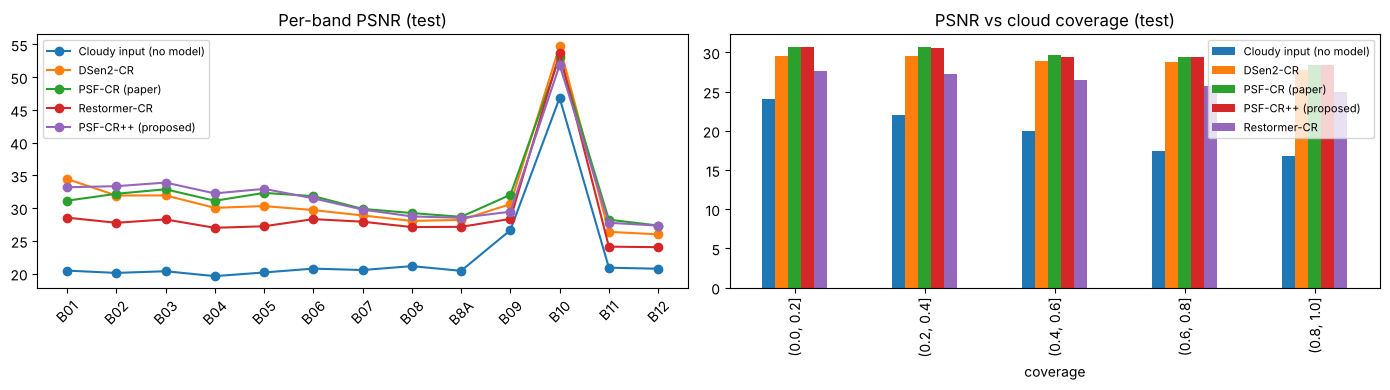

In [39]:
cov_bins = [0, .2, .4, .6, .8, 1.0]; band_psnr, cov_rows = {}, []
for name, df in per_image.items():
    band_psnr[name] = df[[f"PSNR_{b}" for b in BANDS]].mean().values
    lv = pd.cut(df.cloud_cover, cov_bins)
    for l, g in df.groupby(lv, observed=True): cov_rows.append({"Model": name, "coverage": str(l), "PSNR": g.PSNR.mean(), "n": len(g)})
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for nme, v in band_psnr.items(): ax[0].plot(BANDS, v, "o-", label=nme)
ax[0].set_title("Per-band PSNR (test)"); ax[0].tick_params(axis="x", rotation=45); ax[0].legend(fontsize=8)
cov_df = pd.DataFrame(cov_rows); cov_df.pivot(index="coverage", columns="Model", values="PSNR").plot.bar(ax=ax[1]); ax[1].set_title("PSNR vs cloud coverage (test)"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(EVAL_DIR, "band_and_coverage.png"), dpi=110); plt.show()
pd.DataFrame(band_psnr, index=BANDS).round(3).to_csv(os.path.join(EVAL_DIR, "per_band_psnr.csv")); cov_df.round(3).to_csv(os.path.join(EVAL_DIR, "psnr_vs_coverage.csv"), index=False)

## 40. Model Comparison Chart
Bar charts of the four test metrics for all models.

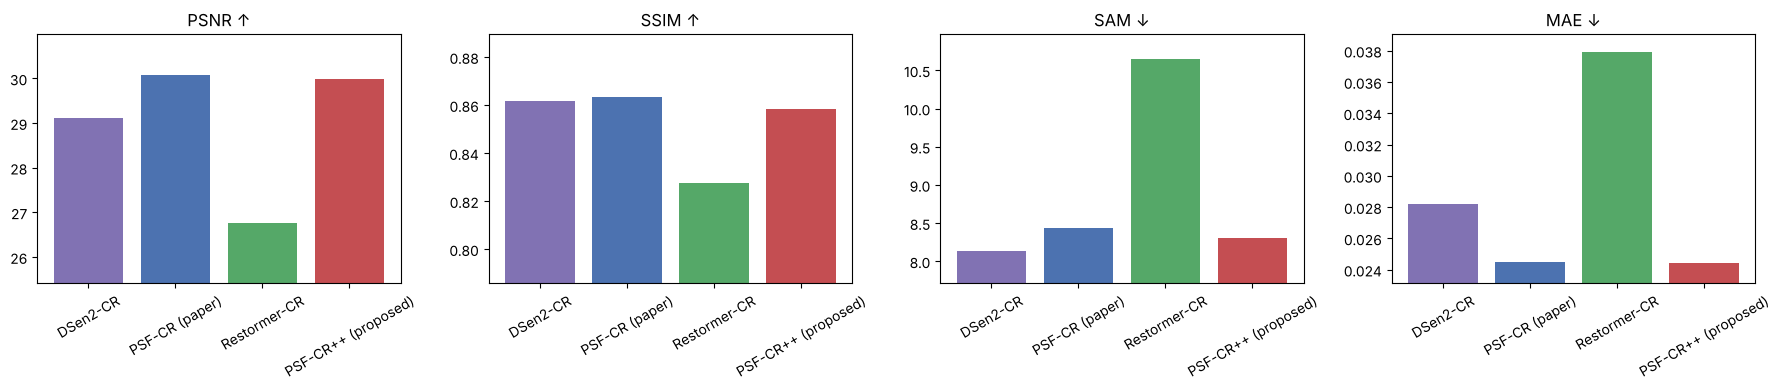

In [40]:
fig, ax = plt.subplots(1, 4, figsize=(18, 4)); r = results[results.Model != "Cloudy input (no model)"]
for a, met in zip(ax, ["PSNR", "SSIM", "SAM", "MAE"]):
    a.bar(r.Model, r[met], color=["#8172B3", "#4C72B0", "#55A868", "#C44E52"][:len(r)]); a.set_title(met + (" ↑" if met in ("PSNR", "SSIM") else " ↓"))
    a.tick_params(axis="x", rotation=30); a.set_ylim(r[met].min() * 0.95, r[met].max() * 1.03)
plt.tight_layout(); plt.savefig(os.path.join(EVAL_DIR, "model_comparison.png"), dpi=110); plt.show()

## 41. Qualitative Comparison
Shows cloudy input, mask, SAR, cloud-free reference and every model's reconstruction (RGB) for three test patches.

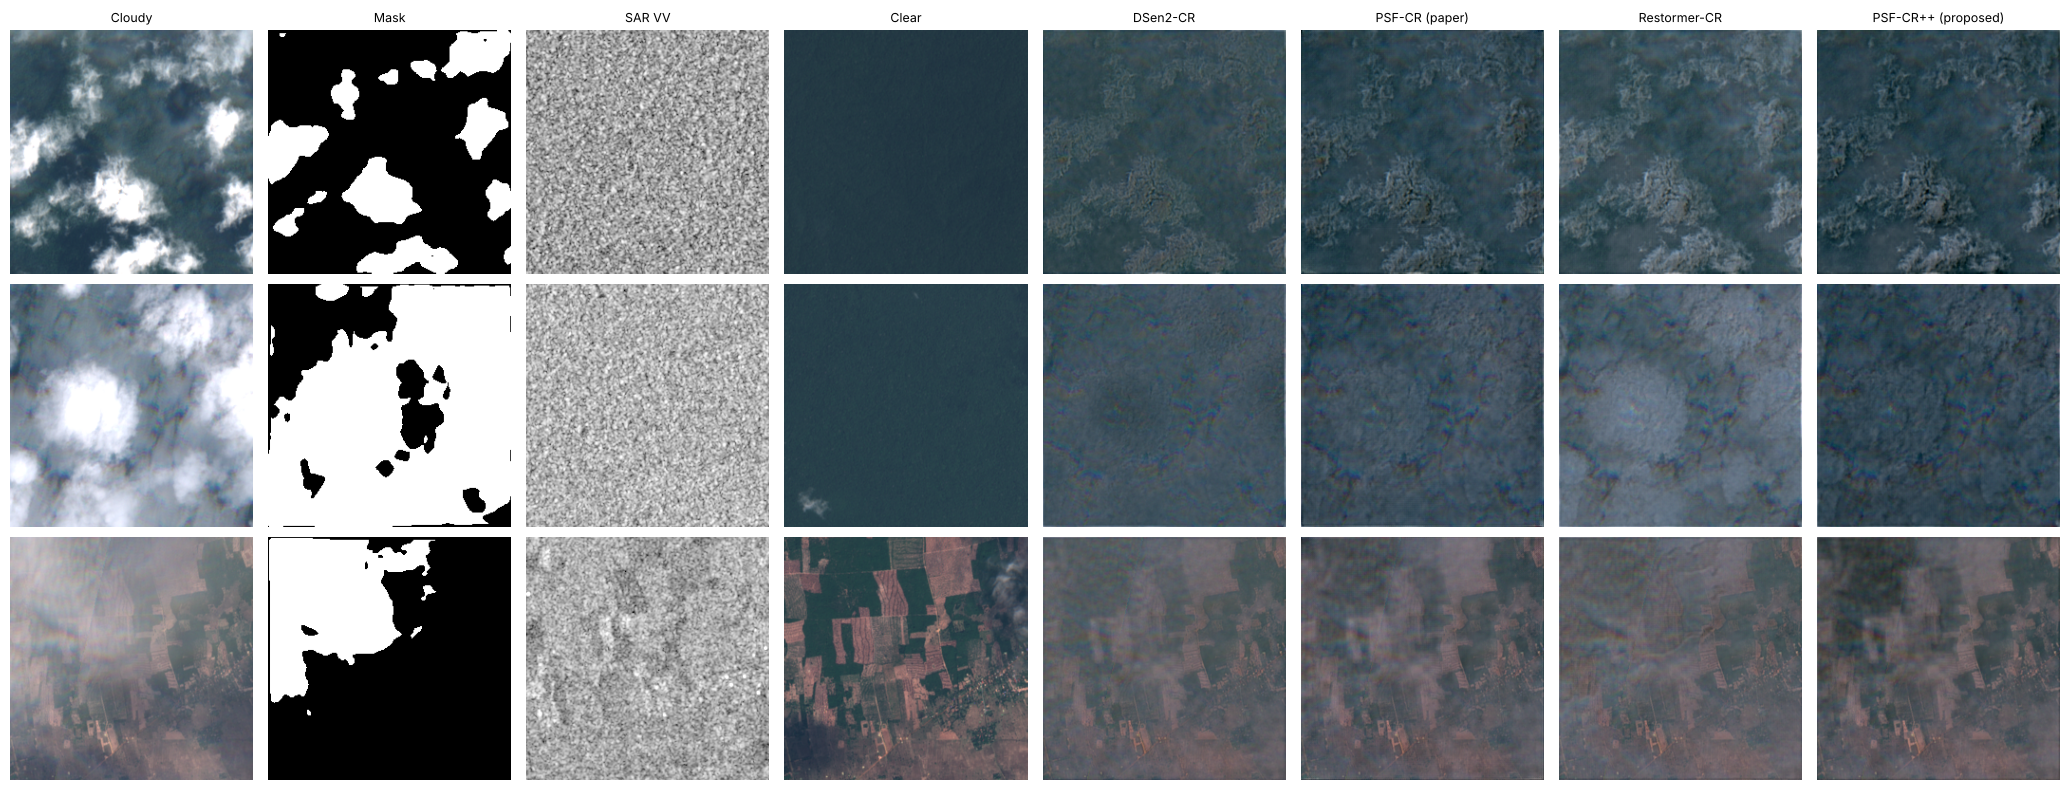

In [41]:
sar, opt, mask, tgt = next(iter(DataLoader(test_ds, 3, shuffle=True, generator=torch.Generator().manual_seed(SEED))))
to_rgb = lambda x: np.clip(x[[3, 2, 1]].permute(1, 2, 0).numpy() * 3.3, 0, 1)
with torch.no_grad(): preds = {k: m(sar, opt, mask)[0].clamp(0, 1) for k, m in trained.items()}
cols = ["Cloudy", "Mask", "SAR VV", "Clear"] + [MODEL_SPECS[k]["display"] for k in preds]
fig, ax = plt.subplots(3, len(cols), figsize=(2.6 * len(cols), 8))
for i in range(3):
    imgs = [to_rgb(opt[i]), mask[i, 0].numpy(), sar[i, 0].numpy(), to_rgb(tgt[i])] + [to_rgb(p[i]) for p in preds.values()]
    for j, im in enumerate(imgs):
        ax[i, j].imshow(im, cmap="gray" if im.ndim == 2 else None); ax[i, j].axis("off")
        if i == 0: ax[i, j].set_title(cols[j], fontsize=9)
plt.tight_layout(); plt.savefig(os.path.join(EVAL_DIR, "qualitative_comparison.png"), dpi=100); plt.show()

## 42. Select the Best Model
Ranks models on the test set by average rank over PSNR↑, SSIM↑, SAM↓, MAE↓ (ties broken by PSNR).

In [42]:
r = results[results.Model != "Cloudy input (no model)"].copy()
r["rank"] = (r.PSNR.rank(ascending=False) + r.SSIM.rank(ascending=False) + r.SAM.rank() + r.MAE.rank()) / 4
r = r.sort_values(["rank", "PSNR"], ascending=[True, False])
best_display = r.iloc[0].Model; best_key = [k for k in MODEL_SPECS if MODEL_SPECS[k]["display"] == best_display][0]
r.to_csv(os.path.join(EVAL_DIR, "model_ranking.csv"), index=False)
print("Best model:", best_display, f"({best_key})"); r[["Model", "PSNR", "SSIM", "SAM", "MAE", "rank"]]

Best model: PSF-CR (paper) (psfcr)


,Model,PSNR,SSIM,SAM,MAE,rank
2,PSF-CR (paper),30.0822,0.8635,8.4417,0.0245,1.75
4,PSF-CR++ (proposed),29.9823,0.8583,8.3046,0.0244,2.00
1,DSen2-CR,29.1190,0.8618,8.1288,0.0282,2.25
3,Restormer-CR,26.7690,0.8275,10.6497,0.0379,4.00


## 43. Verify All Saved Models
Reloads every saved `.pth` checkpoint into a fresh network and confirms it reproduces the stored test PSNR on 8 test patches.

In [43]:
chk_dl = DataLoader(torch.utils.data.Subset(test_ds, range(8)), 4)
for k in MODEL_SPECS:
    files = sorted(os.listdir(os.path.join(MODEL_DIR, k)))
    m = build_model(k); m.load_state_dict(torch.load(os.path.join(MODEL_DIR, k, f"{k}.pth"), map_location="cpu"))
    a, b = evaluate(m, chk_dl)["PSNR"], per_image[MODEL_SPECS[k]["display"]].PSNR[:8].mean()
    print(f"{k:13s} files={files} | reloaded PSNR(8 test imgs) = {a:.4f} vs in-memory {b:.4f}"); assert abs(a - b) < 1e-3

dsen2cr       files=['dsen2cr.pth', 'model_config.json', 'preprocessing.json', 'test_metrics.json', 'training_history.csv'] | reloaded PSNR(8 test imgs) = 28.7237 vs in-memory 28.7237


psfcr         files=['model_config.json', 'preprocessing.json', 'psfcr.pth', 'test_metrics.json', 'training_history.csv'] | reloaded PSNR(8 test imgs) = 28.6333 vs in-memory 28.6333


restormer_cr  files=['model_config.json', 'preprocessing.json', 'restormer_cr.pth', 'test_metrics.json', 'training_history.csv'] | reloaded PSNR(8 test imgs) = 27.1159 vs in-memory 27.1159


psfcr_plus    files=['model_config.json', 'preprocessing.json', 'psfcr_plus.pth', 'test_metrics.json', 'training_history.csv'] | reloaded PSNR(8 test imgs) = 28.6733 vs in-memory 28.6733


## 44. Save the Best Model
Exports the best model as TorchScript (self-contained, no class code needed), plus its state dict, configuration, preprocessing settings and test metrics into `models/best_model/`.

In [44]:
BEST_DIR = os.path.join(MODEL_DIR, "best_model"); os.makedirs(BEST_DIR, exist_ok=True)
best = trained[best_key].cpu().eval()
P = PREPROC["patch_size"]
example = (torch.rand(1, 2, P, P), torch.rand(1, 13, P, P), torch.zeros(1, 1, P, P))
class Wrapper(nn.Module):
    def __init__(s, m): super().__init__(); s.m = m
    def forward(s, sar, opt, mask): return s.m(sar, opt, mask)[0].clamp(0, 1)
with torch.no_grad(): scripted = torch.jit.trace(Wrapper(best), example, check_trace=False)
scripted.save(os.path.join(BEST_DIR, "best_model_torchscript.pt"))
torch.save(best.state_dict(), os.path.join(BEST_DIR, "best_model_state_dict.pth"))
json.dump(PREPROC, open(os.path.join(BEST_DIR, "preprocessing.json"), "w"), indent=2)
best_metrics = results[results.Model == best_display].iloc[0].to_dict()
json.dump({"model_key": best_key, "display_name": best_display, "spec": MODEL_SPECS[best_key], "input_size": [P, P],
           "inputs": {"sar": "(1,2,256,256) VV,VH normalised", "opt": "(1,13,256,256) cloudy S2 normalised", "mask": "(1,1,256,256) binary cloud mask"},
           "output": "(1,13,256,256) cloud-free S2 reflectance in [0,1] (x10000 = L1C DN)", "test_metrics": best_metrics},
          open(os.path.join(BEST_DIR, "best_model_config.json"), "w"), indent=2, default=float)
with torch.no_grad():
    chk = scripted(*[v[:1] for v in next(iter(test_dl))[:3]]); ref = Wrapper(best)(*[v[:1] for v in next(iter(test_dl))[:3]])
print("TorchScript max abs diff vs eager:", float((chk - ref).abs().max())); print(os.listdir(BEST_DIR))

TorchScript max abs diff vs eager: 0.0
['best_model_torchscript.pt', 'best_model_state_dict.pth', 'best_model_config.json', 'preprocessing.json']


## 45. Save Final Summary
Writes the overall summary (results table, best model, split info) to `models/model_evaluation_results/summary.json`.

In [45]:
summary = {"dataset": {"n_patches": int(len(meta)), **meta.split.value_counts().to_dict(), "test_rois": test_rois, "val_rois": val_rois},
           "train_cfg": {k: list(v) if isinstance(v, tuple) else v for k, v in TRAIN_CFG.items()},
           "results": results.to_dict("records"), "best_model": best_display}
json.dump(summary, open(os.path.join(EVAL_DIR, "summary.json"), "w"), indent=2, default=float)
print(json.dumps(summary["results"], indent=1, default=float)[:2000])

[
 {
  "Model": "Cloudy input (no model)",
  "PSNR": 20.9141,
  "SSIM": 0.7366,
  "SAM": 12.7128,
  "MAE": 0.0784,
  "Params (M)": 0.0,
  "Inference (ms/img)": 0.0
 },
 {
  "Model": "DSen2-CR",
  "PSNR": 29.119,
  "SSIM": 0.8618,
  "SAM": 8.1288,
  "MAE": 0.0282,
  "Params (M)": 0.6071,
  "Inference (ms/img)": 406.5584
 },
 {
  "Model": "PSF-CR (paper)",
  "PSNR": 30.0822,
  "SSIM": 0.8635,
  "SAM": 8.4417,
  "MAE": 0.0245,
  "Params (M)": 3.2971,
  "Inference (ms/img)": 852.0819
 },
 {
  "Model": "Restormer-CR",
  "PSNR": 26.769,
  "SSIM": 0.8275,
  "SAM": 10.6497,
  "MAE": 0.0379,
  "Params (M)": 1.1584,
  "Inference (ms/img)": 442.3326
 },
 {
  "Model": "PSF-CR++ (proposed)",
  "PSNR": 29.9823,
  "SSIM": 0.8583,
  "SAM": 8.3046,
  "MAE": 0.0244,
  "Params (M)": 3.6733,
  "Inference (ms/img)": 845.1055
 }
]


## 46. Results and Conclusion
Measured on 254 test patches from 2 held-out regions (full 256×256, all 13 bands):

| Model | PSNR ↑ | SSIM ↑ | SAM ↓ | MAE ↓ | Params (M) |
|---|---|---|---|---|---|
| Cloudy input (no model) | 20.91 | 0.737 | 12.71 | 0.0784 | – |
| DSen2-CR | 29.12 | 0.862 | **8.13** | 0.0282 | 0.61 |
| **PSF-CR (paper)** | **30.08** | **0.864** | 8.44 | 0.0245 | 3.30 |
| Restormer-CR | 26.77 | 0.828 | 10.65 | 0.0379 | 1.16 |
| PSF-CR++ (proposed) | 29.98 | 0.858 | 8.30 | **0.0244** | 3.67 |

* **Best model (average rank over the 4 metrics): PSF-CR**, saved to `models/best_model/`. It improves on the cloudy input by +9.2 dB PSNR and on DSen2-CR by +0.96 dB.
* PSF-CR++ is a close second: it has the lowest MAE and the highest PSNR inside cloudy regions (29.37 dB vs 29.33 dB), but slightly lower PSNR/SSIM overall.
* Restormer-CR (early fusion, no SAR-optical alignment) is clearly weaker, which supports the paper's claim that explicit cross-modal alignment and mask guidance matter.
* All models degrade gracefully as cloud cover rises (PSF-CR: 30.8 dB at ≤20 % cloud → 28.4 dB at >80 % cloud).
* Training was CPU-only (6 epochs, 128×128 crops, batch 4), so absolute numbers are not comparable to the paper's GPU results, but every model used identical data, splits, loss and budget.
